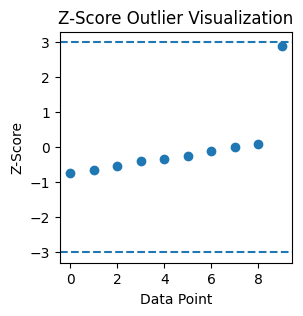

In [2]:
from IPython.core.pylabtools import figsize
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore

data = np.array([10, 12, 15, 18, 20, 22, 25, 28, 30, 100])

z_scores = zscore(data)
plt.figure(figsize=(3,3))
plt.scatter(range(len(data)), z_scores)

plt.axhline(3, linestyle="--")
plt.axhline(-3, linestyle="--")

plt.xlabel("Data Point")
plt.ylabel("Z-Score")
plt.title("Z-Score Outlier Visualization")

plt.show()

{'whiskers': [<matplotlib.lines.Line2D at 0x2b1234982d0>,
 'caps': [<matplotlib.lines.Line2D at 0x2b123498550>,
 'boxes': [<matplotlib.lines.Line2D at 0x2b123498190>],
 'medians': [<matplotlib.lines.Line2D at 0x2b123498f50>],
 'fliers': [<matplotlib.lines.Line2D at 0x2b123498e10>],
 'means': []}

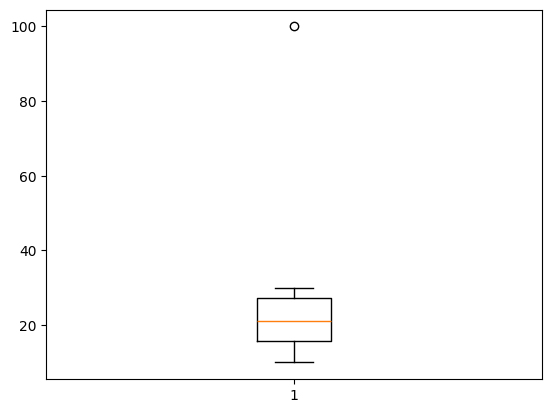

In [3]:
plt.boxplot(data)

In [5]:
import  seaborn as sns
import pandas as pd

In [8]:
df=sns.load_dataset("tips")

In [9]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<Figure size 100x200 with 0 Axes>

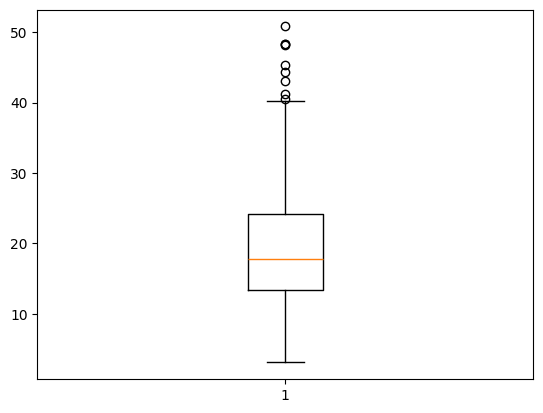

<Figure size 100x200 with 0 Axes>

In [27]:
plt.boxplot(df['total_bill'])
plt.figure(figsize=(1,2))

In [ ]:
q1 =df['total_bill'].quantile(0.25)
q3=df['total_bill'].quantile(0.75)
iqr=q3-q1


lower =q1-1.5*iqr
upper = q3+1.5*iqr
(df['total_bill']<upper)
(df["total_bill"]>lower)

<bound method Series.count of 0      True
1      True
2      True
3      True
4      True
       ... 
239    True
240    True
241    True
242    True
243    True
Name: total_bill, Length: 244, dtype: bool>

iqr------- 1.5625
lower-------- -0.34375
upper----- 5.90625


{'whiskers': [<matplotlib.lines.Line2D at 0x2b1278f8f50>,
 'caps': [<matplotlib.lines.Line2D at 0x2b1278f91d0>,
 'boxes': [<matplotlib.lines.Line2D at 0x2b1278f8e10>],
 'medians': [<matplotlib.lines.Line2D at 0x2b1278f9450>],
 'fliers': [<matplotlib.lines.Line2D at 0x2b1278f9590>],
 'means': []}

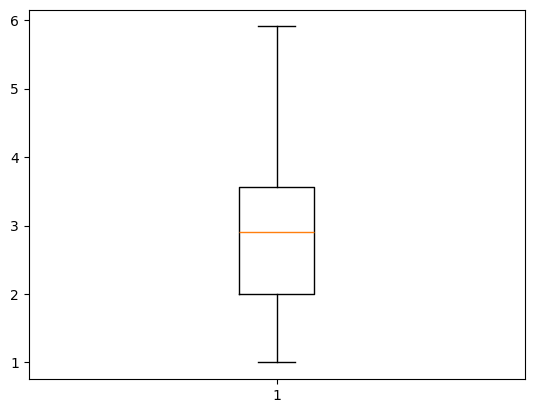

In [29]:
q1 =df['tip'].quantile(0.25)
q3=df['tip'].quantile(0.75)
iqr=q3-q1
print("iqr-------",iqr)


lower =q1-1.5*iqr
print("lower--------",lower)
upper = q3+1.5*iqr
(df['total_bill']<upper)
print('upper-----',upper)
df['tip']=df['tip'].clip(upper=upper)
plt.boxplot(df['tip'])

In [28]:
import pandas as ps

In [16]:
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [17]:
from sklearn.preprocessing import StandardScaler,OneHotEncoder,LabelBinarizer
from sklearn.compose import ColumnTransformer

In [18]:
df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')

In [19]:
num_fea =['total_bill']
ohe_fea =['sex','smoker']
min_max=['tip']


In [20]:
from sklearn.preprocessing import MinMaxScaler
ColumnTransformer(
    transformers=[('num',StandardScaler(),num_fea),
    ('min_max',MinMaxScaler(),min_max),
    ('cat',OneHotEncoder(drop='first'),ohe_fea),]
    ,remainder = 'passthrough'
)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('min_max', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``featur

In [21]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer

num_fea = ['total_bill']
ohe_fea = ['sex', 'smoker']
min_max = ['tip']

transformer = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_fea),
        ('min_max', MinMaxScaler(), min_max),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), ohe_fea)
    ],
    remainder='passthrough'
)

df_transformed = transformer.fit_transform(df)

print(df_transformed)

[[-0.3147113050904943 0.0011111111111111183 0.0 ... 'Sun' 'Dinner' 2]
 [-1.0632353132988692 0.07333333333333333 1.0 ... 'Sun' 'Dinner' 3]
 [0.13777989987156145 0.27777777777777773 1.0 ... 'Sun' 'Dinner' 3]
 ...
 [0.3246295019205694 0.1111111111111111 1.0 ... 'Sat' 'Dinner' 2]
 [-0.2212865040659901 0.08333333333333331 1.0 ... 'Sat' 'Dinner' 2]
 [-0.11322890288102155 0.2222222222222222 0.0 ... 'Thur' 'Dinner' 2]]


In [22]:
import seaborn as sns

df = sns.load_dataset('tips')
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [23]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer

num_fea = ['total_bill']
ohe_fea = ['sex', 'smoker']
min_max = ['tip']

transformer = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_fea),
        ('min_max', MinMaxScaler(), min_max),
        ('cat', OneHotEncoder(drop='first'), ohe_fea)
    ],
    remainder='passthrough'
)

df_transformed = transformer.fit_transform(df)


In [24]:
df_transformed

array([[-0.3147113050904943, 0.0011111111111111183, 0.0, ..., 'Sun',
        'Dinner', 2],
       [-1.0632353132988692, 0.07333333333333333, 1.0, ..., 'Sun',
        'Dinner', 3],
       [0.13777989987156145, 0.27777777777777773, 1.0, ..., 'Sun',
        'Dinner', 3],
       ...,
       [0.3246295019205694, 0.1111111111111111, 1.0, ..., 'Sat',
        'Dinner', 2],
       [-0.2212865040659901, 0.08333333333333331, 1.0, ..., 'Sat',
        'Dinner', 2],
       [-0.11322890288102155, 0.2222222222222222, 0.0, ..., 'Thur',
        'Dinner', 2]], shape=(244, 7), dtype=object)

In [30]:
import pandas as pd
pd.DataFrame(transformer.fit_transform(df),columns=transformer.get_feature_names_out())

,num__total_bill,min_max__tip,cat__sex_Male,cat__smoker_Yes,remainder__day,remainder__time,remainder__size
0,-0.314711,0.001111,0.0,0.0,Sun,Dinner,2
1,-1.063235,0.073333,1.0,0.0,Sun,Dinner,3
2,0.13778,0.277778,1.0,0.0,Sun,Dinner,3
3,0.438315,0.256667,1.0,0.0,Sun,Dinner,2
4,0.540745,0.29,0.0,0.0,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,1.040511,0.546667,1.0,0.0,Sat,Dinner,3
240,0.832275,0.111111,0.0,1.0,Sat,Dinner,2
241,0.32463,0.111111,1.0,1.0,Sat,Dinner,2
242,-0.221287,0.083333,1.0,0.0,Sat,Dinner,2


In [31]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("preprocessor", transformer),
    ("classifier", LogisticRegression())
])

model.fit(x,y)

NameError: name 'x' is not defined

In [32]:
import numpy as np

def simple_linear_regression(X, Y):
    x_mean = np.mean(X)
    y_mean = np.mean(Y)

 
    m = np.sum((X - x_mean) * (Y - y_mean)) / np.sum((X - x_mean) ** 2)

    
    c = y_mean - m * x_mean

    return m, c

In [33]:
X = np.array([1, 2, 3, 4, 5])
Y = np.array([20, 40, 60, 80, 100])

coefficient, intercept = simple_linear_regression(X, Y)

print("Coefficient (Slope):", coefficient)
print("Intercept:", intercept)

Coefficient (Slope): 20.0
Intercept: 0.0
